# Detecção de garimpo em imagens de satélite da Amazônia com DenseNet121

**Transfer learning e fine-tuning em Redes Neurais Convolucionais**

Machine Learning e Deep Learning · Profa. Polyana Santos Fonseca Nascimento · CESUPA · 2026/2

Classificamos recortes de imagens Sentinel-2 da Amazônia em `sem_garimpo` ou `com_garimpo` com uma DenseNet121 pré-treinada no ImageNet. Comparamos três condições: base congelada, fine-tuning A e fine-tuning B.

## 1. Apresentação

### • **Integrantes**

| Nome | Matrícula |
| --- | --- |
| Gabriel Costa de Miranda | 24070036 |
| João Pedro Silva da Silva | 24070017 |
| Yago Patrick Schnorr Pinto | 24070054 |

### • **Contexto do problema**

Garimpos abertos na floresta deixam marcas visíveis do espaço: clareiras de solo exposto, cavas alagadas e rios com água barrenta. Essas marcas aparecem em imagens de satélite gratuitas, como as do Sentinel-2, que cobrem toda a Amazônia a cada poucos dias.

A área a vigiar, porém, é grande demais para inspeção visual de cada imagem. Um classificador automático pode fazer a primeira triagem e apontar onde vale a pena olhar com atenção.

### • **O que se classifica e finalidade**

Cada amostra é um recorte RGB de 128 × 128 pixels de um mosaico Sentinel-2. Com resolução de 10 m, o recorte cobre cerca de 1,28 km × 1,28 km. O modelo responde a uma pergunta binária: o recorte está em uma área de garimpo (`com_garimpo`) ou não (`sem_garimpo`)?

Uma finalidade possível é a **triagem para fiscalização**: aplicar o modelo a grandes áreas e priorizar, para análise de especialistas ou de órgãos ambientais, os recortes com maior probabilidade de garimpo. Nesse uso, o erro mais grave é o falso negativo, um garimpo que passa sem ser detectado.

### • **Dataset e justificativa da escolha**

Usamos o [Dataset Amazonia Garimpo Binario](https://www.kaggle.com/datasets/leogrupioni/dataset-amazonia-garimpo-binario), publicado no Kaggle por Leonardo Grupioni. A construção do dataset é descrita no artigo de Grupioni, Almeida, Gallois e Ranzini, *Detecção de Garimpo na Amazônia com Visão Computacional e Redes Neurais Convolucionais*, Revista Eletrônica de Iniciação Científica em Computação, 2026, [doi:10.5753/reic.2026.7570](https://doi.org/10.5753/reic.2026.7570).

Justificativa da escolha:

- **Relevância:** trata de um problema ambiental real da Amazônia, com uso prático em monitoramento.
- **Origem confiável e rastreável:** as imagens vêm do Sentinel-2 (nível 2A, com máscara de nuvens) e os rótulos vêm dos polígonos de garimpo da RAISG. Um arquivo de manifesto liga cada recorte às suas coordenadas e à fração de sobreposição com os polígonos.
- **Tamanho e equilíbrio:** cerca de 111 mil imagens, com as duas classes em proporções próximas. Isso atende com folga ao mínimo de 1.000 imagens e 100 por classe e permite trabalhar com uma amostra.
- **Pouco explorado:** é um dataset recente, de 2026, não trabalhado em sala.

Trabalhamos com uma amostra estratificada de 20.000 imagens para manter o tempo de treino viável nas três condições.

## 2. Dados

#### Bibliotecas e configuração

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import StratifiedGroupKFold
import tensorflow as tf
from tensorflow import keras
import kagglehub

SEMENTE = 42
NOMES_CLASSES = ["sem_garimpo", "com_garimpo"]
keras.utils.set_random_seed(SEMENTE)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.15.1
GPU: []


E0000 00:00:1794771768.413041  280080 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


#### Download dos dados pelo kagglehub

In [2]:
PASTA_DADOS = Path(kagglehub.dataset_download("leogrupioni/dataset-amazonia-garimpo-binario", output_dir="dados/kaggle"))
PASTA_IMAGENS = PASTA_DADOS / "dataset_amazonia_garimpo_binario"
print(sorted(p.name for p in PASTA_IMAGENS.iterdir()))

['com_garimpo', 'manifesto_chips.csv', 'sem_garimpo']


#### Inspeção dos arquivos

In [3]:
caminhos = [p for p in PASTA_IMAGENS.rglob("*") if p.is_file()]
arquivos = pd.DataFrame({
    "pasta": [p.parent.name for p in caminhos],
    "extensao": [p.suffix for p in caminhos]})
pd.crosstab(arquivos.pasta, arquivos.extensao, margins=True, margins_name="total")

extensao,.csv,.png,total
pasta,,,
com_garimpo,0,55541,55541
dataset_amazonia_garimpo_binario,1,0,1
sem_garimpo,0,56043,56043
total,1,111584,111585


#### Entendendo o manifesto.csv

In [4]:
manifesto = pd.read_csv(PASTA_IMAGENS / "manifesto_chips.csv")
print(manifesto.shape)
manifesto.label_str.value_counts()

(111584, 27)


label_str
sem_garimpo    56043
com_garimpo    55541
Name: count, dtype: int64

In [5]:
# Colunas que descrevem a origem dos recortes: têm um único valor em todo o dataset.
manifesto[["tile_size_px", "bands_used", "dtype_src", "utm_epsg"]].drop_duplicates()

,tile_size_px,bands_used,dtype_src,utm_epsg
0,128,"['B4', 'B3', 'B2']",float32,32721


In [6]:
# Os recortes vêm de 12 arquivos .tif vizinhos do mesmo mosaico.
manifesto.groupby("tif_source").label_int.agg(recortes="size", fracao_com_garimpo="mean").round(3)

,recortes,fracao_com_garimpo
tif_source,,
v3_new_ret_s2_median_2024_dry-0000000000-0000000000.tif,11236,0.465
v3_new_ret_s2_median_2024_dry-0000000000-0000013568.tif,11236,0.597
v3_new_ret_s2_median_2024_dry-0000000000-0000027136.tif,11130,0.235
v3_new_ret_s2_median_2024_dry-0000013568-0000000000.tif,11236,0.578
v3_new_ret_s2_median_2024_dry-0000013568-0000013568.tif,11236,0.892
v3_new_ret_s2_median_2024_dry-0000013568-0000027136.tif,11130,0.550
v3_new_ret_s2_median_2024_dry-0000027136-0000000000.tif,11236,0.060
v3_new_ret_s2_median_2024_dry-0000027136-0000013568.tif,11236,0.567
v3_new_ret_s2_median_2024_dry-0000027136-0000027136.tif,11130,0.820


#### Formato das imagens

In [7]:
exemplos = manifesto.groupby("label_str").sample(5, random_state=SEMENTE)
for exemplo in exemplos.itertuples():
    conteudo = tf.io.read_file(str(PASTA_IMAGENS / exemplo.png_path))
    imagem = tf.io.decode_png(conteudo).numpy()
    print(f"{exemplo.label_str}: formato {imagem.shape}, tipo {imagem.dtype}, "
          f"mín {imagem.min()}, máx {imagem.max()}, média {imagem.mean():.1f}")

com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 194, média 7.9
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 97, média 5.2
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 34, média 4.8
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 218, média 13.8
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 45, média 8.1
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 63, média 9.0
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 102, média 6.6
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 44, média 7.0
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 37, média 6.8
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 40, média 7.1


#### Origem dos rótulos
O rótulo vem da sobreposição de cada recorte com polígonos de garimpo da RAISG (`overlap_ratio`).

In [8]:
manifesto.groupby("label_str")['overlap_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
label_str,,,,,,,,
com_garimpo,55541.0,1.003981,0.274265,0.050329,0.999998,1.0,1.0,3.310692
sem_garimpo,56043.0,0.000227,0.002678,0.000000,0.000000,0.0,0.0,0.049813


#### **Resumo da inspeção**

- **Formato:** PNG RGB de 8 bits, 128 × 128 pixels, bandas B4, B3 e B2 do Sentinel-2. Não é preciso converter.
- **Classes:** 56.043 `sem_garimpo` e 55.541 `com_garimpo` (50,2% e 49,8%). Não usaremos `class_weight`.
- **Brilho:** as imagens são escuras (média perto de 8 em 255). Tratamos isso no pré-processamento.
- **Rótulo:** `com_garimpo` quando mais de 5% do recorte cai em um polígono da RAISG. Os polígonos marcam áreas de garimpo, não só o solo exposto; um recorte positivo pode ser quase todo floresta. Verificamos isso visualmente na análise exploratória.
- **Região:** 12 blocos vizinhos, com fração de garimpo de 0% a 89%. As coordenadas permitem dividir os dados por região.

#### Blocos espaciais
Recortes vizinhos mostram a mesma paisagem. Se caírem em divisões diferentes, a validação e o teste ficam otimistas. Por isso agrupamos os recortes em blocos de 8 × 8 (cerca de 10 km de lado), e cada bloco vai inteiro para uma única divisão.

In [9]:
TAMANHO_BLOCO = 8

partes_nome = manifesto.tif_source.str.replace(".tif", "").str.split("-")
linha_tif = partes_nome.str[1].astype(int) // 128
coluna_tif = partes_nome.str[2].astype(int) // 128

tabela = pd.DataFrame({
    "arquivo": manifesto.png_path,
    "rotulo": manifesto.label_int,
    "classe": manifesto.label_str,
    "linha": linha_tif + manifesto.tile_row,
    "coluna": coluna_tif + manifesto.tile_col,
    "overlap_ratio": manifesto.overlap_ratio})

linha_bloco = tabela.linha // TAMANHO_BLOCO
coluna_bloco = tabela.coluna // TAMANHO_BLOCO
tabela["bloco"] = linha_bloco.astype(str) + "_" + coluna_bloco.astype(str)
print("Blocos:", tabela.bloco.nunique())

Blocos: 1760


#### Amostra e divisão
Primeiro repartimos os blocos de todo o dataset em 20 partes com `StratifiedGroupKFold`: 3 para teste, 3 para validação e 14 para treino. Depois sorteamos 14.000, 3.000 e 3.000 imagens, com a mesma proporção de classes em cada divisão.

O resultado fica em `dados/divisao_amostra.csv`. Nas execuções seguintes, o notebook lê esse arquivo em vez de sortear de novo.

In [10]:
CAMINHO_DIVISAO = Path("dados/divisao_amostra.csv")
TAMANHOS = {"treino": 14000, "validacao": 3000, "teste": 3000}

if CAMINHO_DIVISAO.exists():
    amostra = pd.read_csv(CAMINHO_DIVISAO)
else:
    # 1. Reparte os blocos em 20 partes com proporções de classe parecidas
    divisor = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEMENTE)
    tabela["parte"] = 0
    numero = 0
    for indices_fora, indices_da_parte in divisor.split(tabela, tabela.rotulo, groups=tabela.bloco):
        tabela.loc[indices_da_parte, "parte"] = numero
        numero += 1

    # 2. Partes 0 a 2 viram teste, 3 a 5 validação e as demais treino
    tabela["divisao"] = "treino"
    tabela.loc[tabela.parte < 6, "divisao"] = "validacao"
    tabela.loc[tabela.parte < 3, "divisao"] = "teste"

    # 3. Em cada divisão, sorteia o número exato de imagens de cada classe
    proporcao_com = tabela.rotulo.mean()
    sorteios = []
    for divisao, n_imagens in TAMANHOS.items():
        n_com = round(n_imagens * proporcao_com)
        n_sem = n_imagens - n_com
        candidatas = tabela[tabela.divisao == divisao]
        sorteios.append(candidatas[candidatas.rotulo == 0].sample(n_sem, random_state=SEMENTE))
        sorteios.append(candidatas[candidatas.rotulo == 1].sample(n_com, random_state=SEMENTE))
    amostra = pd.concat(sorteios, ignore_index=True).drop(columns="parte")
    amostra.to_csv(CAMINHO_DIVISAO, index=False)

pd.crosstab(amostra.divisao, amostra.classe, margins=True, margins_name="total")

classe,com_garimpo,sem_garimpo,total
divisao,,,
teste,1493,1507,3000
treino,6969,7031,14000
validacao,1493,1507,3000
total,9955,10045,20000


#### Visualizando como ficou a divisão entre **treino**, **teste** e **validação**

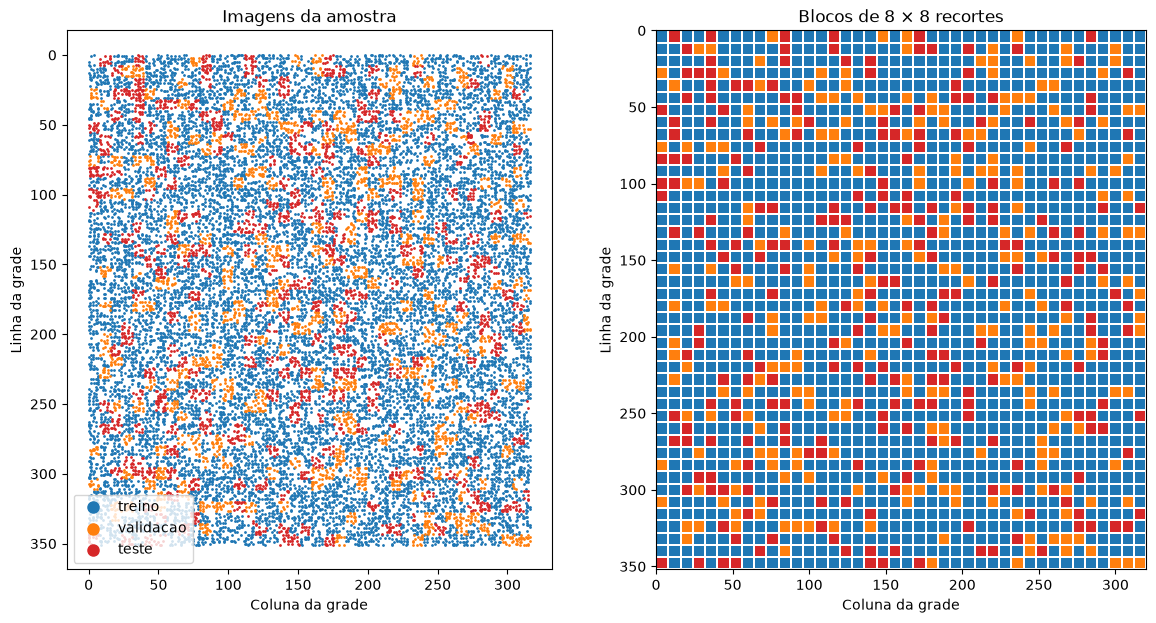

In [11]:
DIVISOES = ["treino", "validacao", "teste"]
CORES = ["tab:blue", "tab:orange", "tab:red"]

n_linhas_blocos = amostra.linha.max() // TAMANHO_BLOCO + 1
n_colunas_blocos = amostra.coluna.max() // TAMANHO_BLOCO + 1
matriz = np.full((n_linhas_blocos, n_colunas_blocos), np.nan)
for imagem in amostra.itertuples():
    matriz[imagem.linha // TAMANHO_BLOCO, imagem.coluna // TAMANHO_BLOCO] = DIVISOES.index(imagem.divisao)

fig, eixos = plt.subplots(1, 2, figsize=(14, 7))

for divisao, cor in zip(DIVISOES, CORES):
    parte = amostra[amostra.divisao == divisao]
    eixos[0].scatter(parte.coluna, parte.linha, s=1, color=cor, label=divisao)
eixos[0].legend(markerscale=8, loc="lower left")
eixos[0].set_title("Imagens da amostra")

bordas_x = np.arange(n_colunas_blocos + 1) * TAMANHO_BLOCO
bordas_y = np.arange(n_linhas_blocos + 1) * TAMANHO_BLOCO
eixos[1].pcolormesh(bordas_x, bordas_y, matriz, cmap=ListedColormap(CORES), edgecolors="white", linewidth=0.3)
eixos[1].set_title(f"Blocos de {TAMANHO_BLOCO} × {TAMANHO_BLOCO} recortes")

for eixo in eixos:
    eixo.set(xlabel="Coluna da grade", ylabel="Linha da grade", aspect="equal")
    eixo.invert_yaxis()
plt.show()

#### Análise exploratória

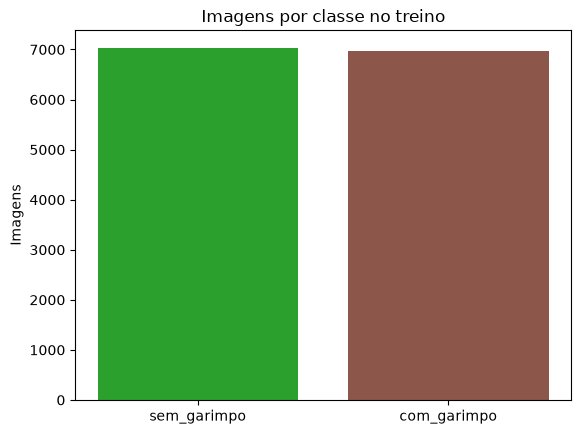

In [12]:
treino = amostra[amostra.divisao == "treino"].reset_index(drop=True)

contagem = treino.classe.value_counts()
plt.bar(contagem.index, contagem.values, color=["tab:green", "tab:brown"])
plt.title("Imagens por classe no treino")
plt.ylabel("Imagens")
plt.show()

#### Exemplos de cada classe

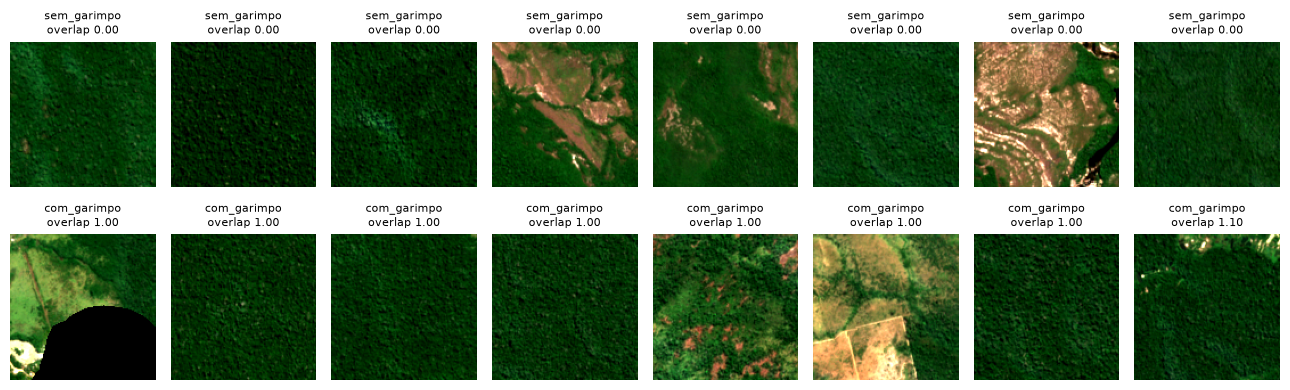

In [13]:
AUMENTO_BRILHO = 3

def ler_imagem(arquivo):
    conteudo = tf.io.read_file(str(PASTA_IMAGENS / arquivo))
    return tf.io.decode_png(conteudo, channels=3).numpy()

fig, eixos = plt.subplots(2, 8, figsize=(13, 4.2))
for linha_eixos, classe in zip(eixos, NOMES_CLASSES):
    exemplos = treino[treino.classe == classe].sample(8, random_state=SEMENTE)
    for eixo, exemplo in zip(linha_eixos, exemplos.itertuples()):
        imagem = ler_imagem(exemplo.arquivo).astype("float32") * AUMENTO_BRILHO
        eixo.imshow(np.clip(imagem, 0, 255).astype("uint8"))
        eixo.set_title(f"{classe}\noverlap {exemplo.overlap_ratio:.2f}", fontsize=8)
        eixo.axis("off")
plt.tight_layout()
plt.show()

#### Cor e brilho por classe

In [14]:
medias = []
for arquivo in treino.arquivo:
    imagem = ler_imagem(arquivo)
    medias.append(imagem.mean(axis=(0, 1)))

cores = pd.DataFrame(medias, columns=["R", "G", "B"])
cores["classe"] = treino.classe
cores.groupby("classe").agg(["mean", "std"]).round(1)

R           G          B     
             mean   std  mean   std mean  std
classe                                       
com_garimpo  12.5  20.6  23.5  12.2  7.1  8.8
sem_garimpo   3.6   6.5  18.7   4.9  3.4  3.5

Aqui da para notar uma diferença entre as médias de cor por classe, a média da cores na classe "com_garimpo" é maior do que na classe "sem_garimpo". Entretanto o desvio padrão muda muito, isso provavelmente se deve a áreas que estão classificadas como "com_garimpo" mas são áreas de preservação daquele garimpo (no caso de garimpos legais).

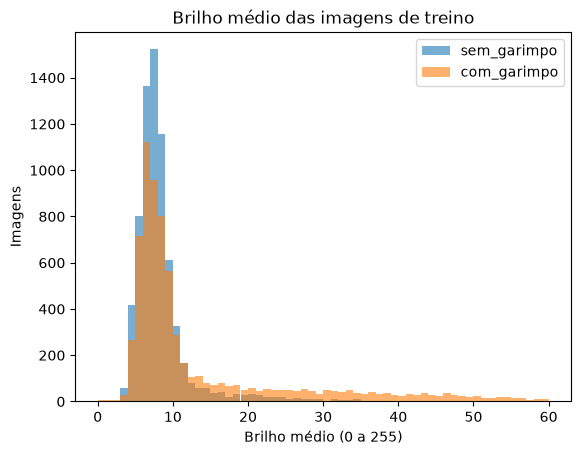

In [15]:
cores["brilho"] = cores[["R", "G", "B"]].mean(axis=1)

for classe in NOMES_CLASSES:
    plt.hist(cores.brilho[cores.classe == classe], bins=60, range=(0, 60), alpha=0.6, label=classe)
plt.title("Brilho médio das imagens de treino")
plt.xlabel("Brilho médio (0 a 255)")
plt.ylabel("Imagens")
plt.legend()
plt.show()

#### Brilho por faixa de overlap

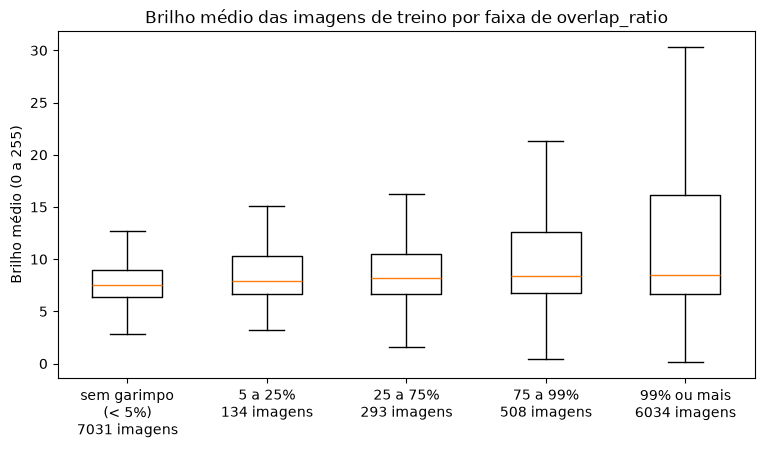

In [16]:
def faixa_overlap(overlap):
    if overlap < 0.05:
        return "sem garimpo\n(< 5%)"
    if overlap < 0.25:
        return "5 a 25%"
    if overlap < 0.75:
        return "25 a 75%"
    if overlap < 0.99:
        return "75 a 99%"
    return "99% ou mais"

cores["faixa"] = treino.overlap_ratio.map(faixa_overlap)
FAIXAS = ["sem garimpo\n(< 5%)", "5 a 25%", "25 a 75%", "75 a 99%", "99% ou mais"]

brilho_por_faixa = [cores.brilho[cores.faixa == faixa] for faixa in FAIXAS]
nomes_eixo = [f"{faixa}\n{len(brilhos)} imagens" for faixa, brilhos in zip(FAIXAS, brilho_por_faixa)]

plt.figure(figsize=(9, 4.5))
plt.boxplot(brilho_por_faixa, tick_labels=nomes_eixo, showfliers=False)
plt.title("Brilho médio das imagens de treino por faixa de overlap_ratio")
plt.ylabel("Brilho médio (0 a 255)")
plt.show()

#### Onde está o garimpo

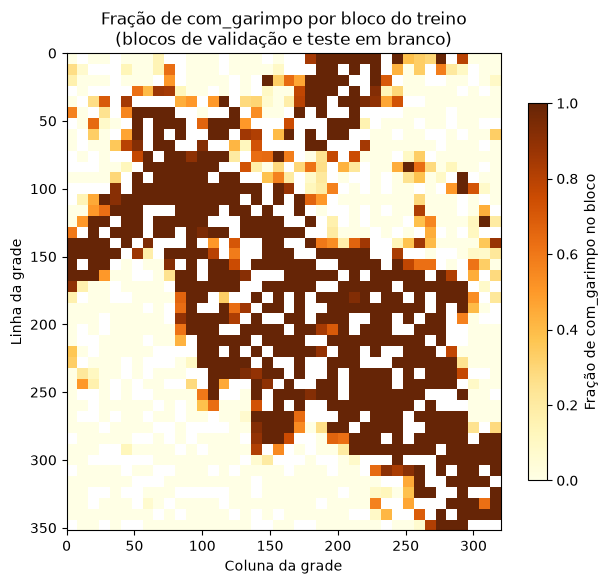

In [17]:
fracao_por_bloco = treino.groupby("bloco").rotulo.mean()

matriz_fracao = np.full((n_linhas_blocos, n_colunas_blocos), np.nan)
for bloco, fracao in fracao_por_bloco.items():
    linha_bloco, coluna_bloco = bloco.split("_")
    matriz_fracao[int(linha_bloco), int(coluna_bloco)] = fracao

plt.figure(figsize=(7, 7))
plt.pcolormesh(bordas_x, bordas_y, matriz_fracao, cmap="YlOrBr", vmin=0, vmax=1)
plt.colorbar(label="Fração de com_garimpo no bloco", shrink=0.7)
plt.title("Fração de com_garimpo por bloco do treino\n(blocos de validação e teste em branco)")
plt.xlabel("Coluna da grade")
plt.ylabel("Linha da grade")
plt.gca().set_aspect("equal")
plt.gca().invert_yaxis()
plt.show()

#### Áreas mascaradas (pixels pretos)

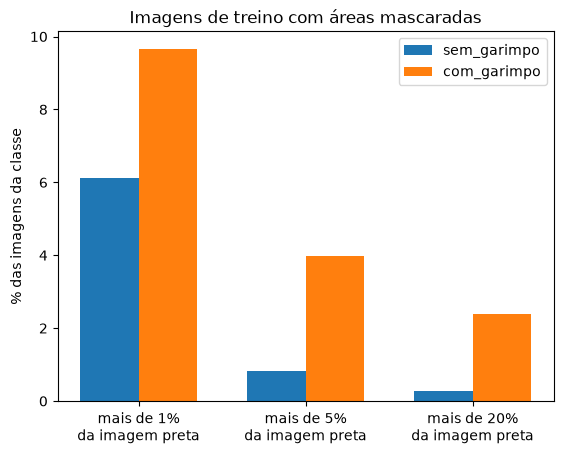

In [18]:
fracao_preta = []
for arquivo in treino.arquivo:
    imagem = ler_imagem(arquivo)
    pixels_pretos = imagem.sum(axis=2) == 0
    fracao_preta.append(pixels_pretos.mean())
cores["fracao_preta"] = fracao_preta

LIMITES = [0.01, 0.05, 0.20]
largura = 0.35
posicoes = np.arange(len(LIMITES))
for deslocamento, classe in zip([-largura / 2, largura / 2], NOMES_CLASSES):
    imagens_classe = cores[cores.classe == classe]
    percentuais = [100 * (imagens_classe.fracao_preta > limite).mean() for limite in LIMITES]
    plt.bar(posicoes + deslocamento, percentuais, largura, label=classe)

plt.xticks(posicoes, [f"mais de {limite:.0%}\nda imagem preta" for limite in LIMITES])
plt.title("Imagens de treino com áreas mascaradas")
plt.ylabel("% das imagens da classe")
plt.legend()
plt.show()